In [1]:
import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)
import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

/kaggle/input/notebooks/muhammedabdulazeem/garbage-classification/__results__.html
/kaggle/input/notebooks/muhammedabdulazeem/garbage-classification/__notebook__.ipynb
/kaggle/input/notebooks/muhammedabdulazeem/garbage-classification/__output__.json
/kaggle/input/notebooks/muhammedabdulazeem/garbage-classification/custom.css
/kaggle/input/notebooks/muhammedabdulazeem/garbage-classification/__results___files/__results___9_26.png
/kaggle/input/notebooks/muhammedabdulazeem/garbage-classification/__results___files/__results___9_18.png
/kaggle/input/notebooks/muhammedabdulazeem/garbage-classification/__results___files/__results___9_5.png
/kaggle/input/notebooks/muhammedabdulazeem/garbage-classification/__results___files/__results___9_59.png
/kaggle/input/notebooks/muhammedabdulazeem/garbage-classification/__results___files/__results___9_69.png
/kaggle/input/notebooks/muhammedabdulazeem/garbage-classification/__results___files/__results___9_33.png
/kaggle/input/notebooks/muhammedabdulazeem/g

In [2]:
os.listdir("/kaggle/input/garbage-classification/garbage_classification/")

['metal',
 'white-glass',
 'biological',
 'paper',
 'brown-glass',
 'battery',
 'trash',
 'cardboard',
 'shoes',
 'clothes',
 'plastic',
 'green-glass']

Total Classes: 12
Total Images: 15515
battery: 945
biological: 985
brown-glass: 607
cardboard: 891
clothes: 5325
green-glass: 629
metal: 769
paper: 1050
plastic: 865
shoes: 1977
trash: 697
white-glass: 775


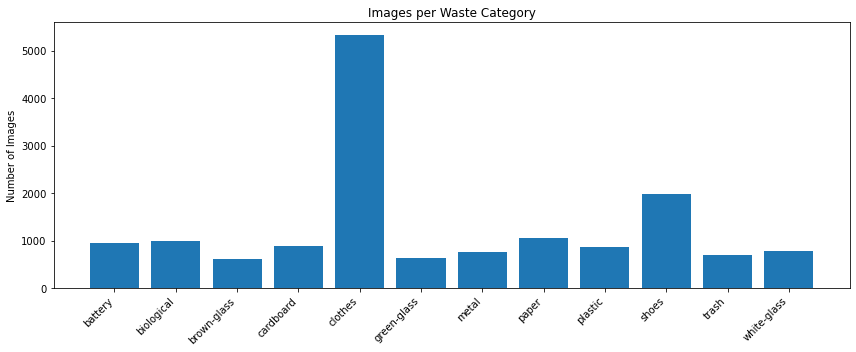

In [3]:
import os
import matplotlib.pyplot as plt

DATASET_PATH = "/kaggle/input/garbage-classification/garbage_classification"

class_counts = {}

for class_name in sorted(os.listdir(DATASET_PATH)):
    class_path = os.path.join(DATASET_PATH, class_name)

    if os.path.isdir(class_path):
        images = [
            f for f in os.listdir(class_path)
            if f.lower().endswith((".jpg", ".jpeg", ".png", ".webp"))
        ]
        class_counts[class_name] = len(images)

print("Total Classes:", len(class_counts))
print("Total Images:", sum(class_counts.values()))

for name, count in class_counts.items():
    print(f"{name}: {count}")

plt.figure(figsize=(12, 5))
plt.bar(class_counts.keys(), class_counts.values())
plt.xticks(rotation=45, ha="right")
plt.ylabel("Number of Images")
plt.title("Images per Waste Category")
plt.tight_layout()
plt.show()

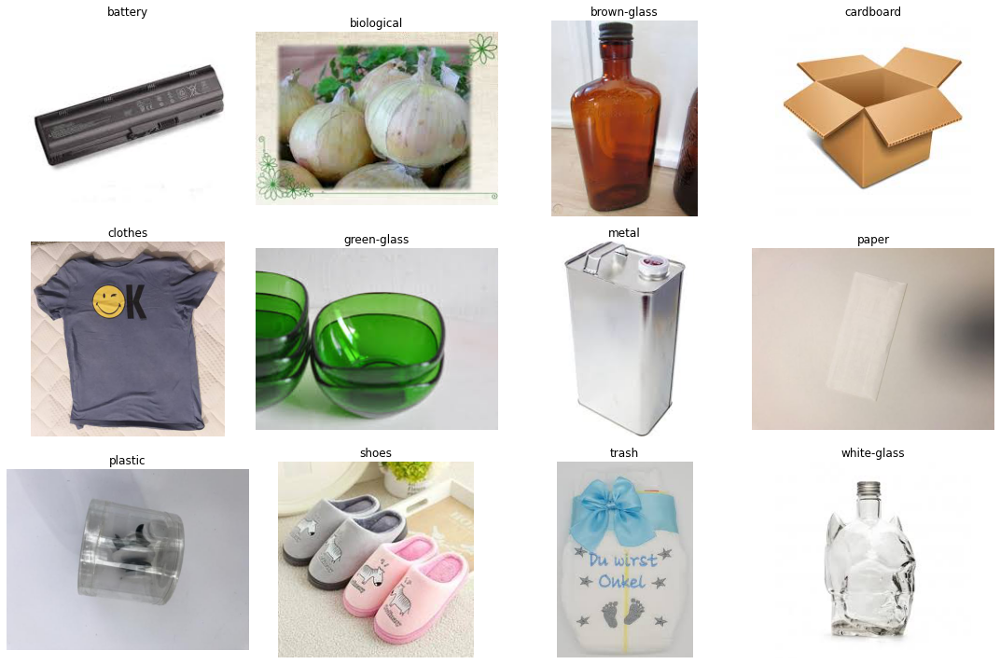

In [4]:

import os
import random
import matplotlib.pyplot as plt
from PIL import Image

DATASET_PATH = "/kaggle/input/garbage-classification/garbage_classification"

random.seed(42)
classes = sorted(os.listdir(DATASET_PATH))

plt.figure(figsize=(15, 10))

for i, class_name in enumerate(classes):
    class_path = os.path.join(DATASET_PATH, class_name)
    images = [
        f for f in os.listdir(class_path)
        if f.lower().endswith((".jpg", ".jpeg", ".png", ".webp"))
    ]

    if images:
        image_path = os.path.join(class_path, random.choice(images))
        img = Image.open(image_path).convert("RGB")

        plt.subplot(3, 4, i + 1)
        plt.imshow(img)
        plt.title(class_name)
        plt.axis("off")

plt.tight_layout()
plt.show()


In [5]:

%%time

import os
import pandas as pd
import numpy as np

DATASET_PATH = "/kaggle/input/garbage-classification/garbage_classification"

records = []

for class_name in sorted(os.listdir(DATASET_PATH)):
    class_path = os.path.join(DATASET_PATH, class_name)

    if not os.path.isdir(class_path):
        continue

    for photo in os.listdir(class_path):
        if photo.lower().endswith((".jpg", ".jpeg", ".png", ".webp")):
            records.append({
                "path": os.path.join(class_path, photo),
                "target": class_name
            })

data = pd.DataFrame(records)

print("Total images:", len(data))
print("Total classes:", data["target"].nunique())
print(data.head())


Total images: 15515
Total classes: 12
                                                path   target
0  /kaggle/input/garbage-classification/garbage_c...  battery
1  /kaggle/input/garbage-classification/garbage_c...  battery
2  /kaggle/input/garbage-classification/garbage_c...  battery
3  /kaggle/input/garbage-classification/garbage_c...  battery
4  /kaggle/input/garbage-classification/garbage_c...  battery
CPU times: user 116 ms, sys: 7.24 ms, total: 123 ms
Wall time: 134 ms


In [6]:
data.shape

(15515, 2)

In [7]:
data.duplicated().sum()

0

In [8]:
data = data.sample(frac=1)
data.reset_index(drop=True, inplace=True)
data.head()

,path,target
0,/kaggle/input/garbage-classification/garbage_c...,clothes
1,/kaggle/input/garbage-classification/garbage_c...,shoes
2,/kaggle/input/garbage-classification/garbage_c...,white-glass
3,/kaggle/input/garbage-classification/garbage_c...,clothes
4,/kaggle/input/garbage-classification/garbage_c...,white-glass


/opt/conda/lib/python3.7/site-packages/seaborn/_decorators.py:43: FutureWarning: Pass the following variable as a keyword arg: x. From version 0.12, the only valid positional argument will be `data`, and passing other arguments without an explicit keyword will result in an error or misinterpretation.
  FutureWarning


(array([ 0,  1,  2,  3,  4,  5,  6,  7,  8,  9, 10, 11]),
 [Text(0, 0, 'clothes'),
  Text(1, 0, 'shoes'),
  Text(2, 0, 'white-glass'),
  Text(3, 0, 'plastic'),
  Text(4, 0, 'paper'),
  Text(5, 0, 'biological'),
  Text(6, 0, 'cardboard'),
  Text(7, 0, 'green-glass'),
  Text(8, 0, 'metal'),
  Text(9, 0, 'trash'),
  Text(10, 0, 'battery'),
  Text(11, 0, 'brown-glass')])

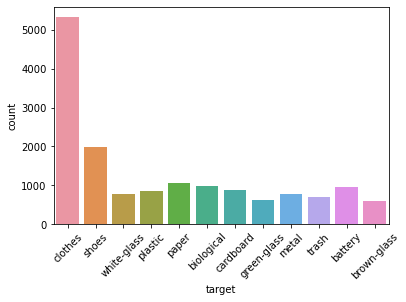

In [9]:
import matplotlib.pyplot as plt
import seaborn as sns

sns.countplot(data['target'])
plt.xticks(rotation="45")

In [10]:
data['target'].value_counts()

clothes        5325
shoes          1977
paper          1050
biological      985
battery         945
cardboard       891
plastic         865
white-glass     775
metal           769
trash           697
green-glass     629
brown-glass     607
Name: target, dtype: int64

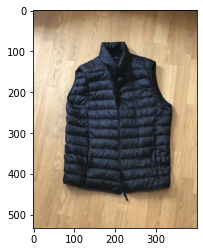

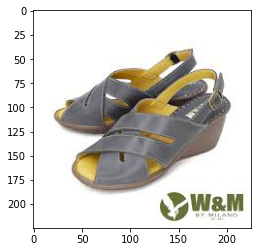

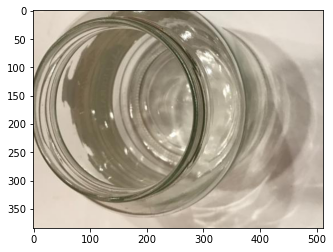

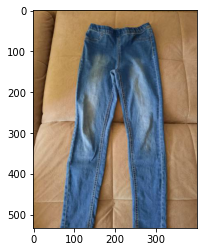

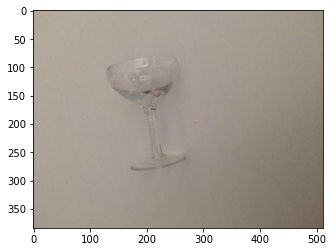

...

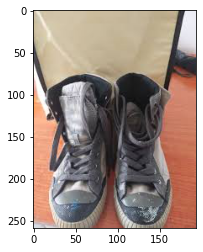

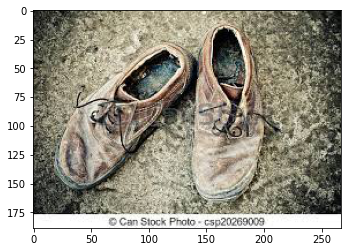

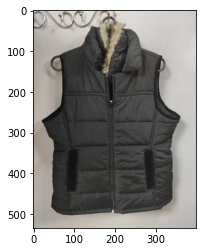

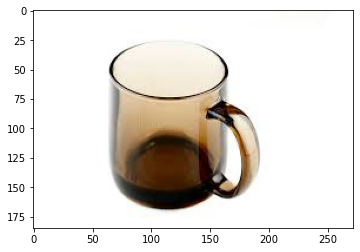

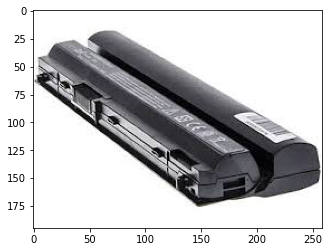

In [11]:
import matplotlib.image as mpimg

for i in range(100):
    image = mpimg.imread(data.loc[i, 'path'])
    plt.imshow(image)
    plt.show()

In [12]:
total_counts = 0

for class_ in os.listdir("/kaggle/input/garbage-classification/garbage_classification/"):
    count_class = 0
    for photo in os.listdir("/kaggle/input/garbage-classification/garbage_classification/" + class_):
        count_class += 1
        total_counts += 1
    print(str(class_) + " has " + str(count_class) + " photos")

metal has 769 photos
white-glass has 775 photos
biological has 985 photos
paper has 1050 photos
brown-glass has 607 photos
battery has 945 photos
trash has 697 photos
cardboard has 891 photos
shoes has 1977 photos
clothes has 5325 photos
plastic has 865 photos
green-glass has 629 photos


In [13]:
total_counts

15515

In [14]:
weights_ = dict()
for class_ in os.listdir("/kaggle/input/garbage-classification/garbage_classification/"):
    count_class = 0
    for photo in os.listdir("/kaggle/input/garbage-classification/garbage_classification/" + class_):
        count_class += 1
    print(str(class_) + " has " + str((count_class/total_counts) * 100) + "% of photos")
    weights_[class_] = 1 - (count_class/total_counts)

metal has 4.956493715758943% of photos
white-glass has 4.995165968417661% of photos
biological has 6.348694811472769% of photos
paper has 6.767644215275539% of photos
brown-glass has 3.912342893973574% of photos
battery has 6.090879793747986% of photos
trash has 4.492426683854334% of photos
cardboard has 5.74282951981953% of photos
shoes has 12.742507251047375% of photos
clothes has 34.32162423461166% of photos
plastic has 5.575249758298421% of photos
green-glass has 4.054141153722204% of photos


In [15]:
weights_

{'metal': 0.9504350628424105,
 'white-glass': 0.9500483403158234,
 'biological': 0.9365130518852723,
 'paper': 0.9323235578472446,
 'brown-glass': 0.9608765710602643,
 'battery': 0.9390912020625202,
 'trash': 0.9550757331614567,
 'cardboard': 0.9425717048018047,
 'shoes': 0.8725749274895263,
 'clothes': 0.6567837576538833,
 'plastic': 0.9442475024170158,
 'green-glass': 0.959458588462778}

In [16]:

from sklearn.model_selection import train_test_split

X_train, X_test = train_test_split(
    data,
    test_size=0.2,
    random_state=42,
    stratify=data["target"]
)

print("Training images:", len(X_train))
print("Testing images:", len(X_test))
print("Training classes:", X_train["target"].nunique())
print("Testing classes:", X_test["target"].nunique())


Training images: 12412
Testing images: 3103
Training classes: 12
Testing classes: 12


In [17]:

from sklearn.model_selection import train_test_split

train_df, val_df = train_test_split(
    X_train,
    test_size=0.125,
    random_state=42,
    stratify=X_train["target"]
)

print("Training:", len(train_df))
print("Validation:", len(val_df))
print("Testing:", len(X_test))


Training: 10860
Validation: 1552
Testing: 3103


In [18]:

import tensorflow as tf
from tensorflow.keras.applications.mobilenet_v2 import (
    MobileNetV2, preprocess_input
)
from tensorflow.keras import layers, models
from tensorflow.keras.utils import Sequence
from PIL import Image
import numpy as np

IMG_SIZE = 224
BATCH_SIZE = 32
NUM_CLASSES = data["target"].nunique()

print("TensorFlow:", tf.__version__)
print("Classes:", NUM_CLASSES)
print("GPU:", tf.config.list_physical_devices("GPU"))


TensorFlow: 2.4.1
Classes: 12
GPU: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU'), PhysicalDevice(name='/physical_device:GPU:1', device_type='GPU')]


In [19]:

from tensorflow.keras.preprocessing.image import ImageDataGenerator

train_datagen = ImageDataGenerator(
    preprocessing_function=preprocess_input,
    rotation_range=15,
    width_shift_range=0.1,
    height_shift_range=0.1,
    horizontal_flip=True
)

valid_datagen = ImageDataGenerator(
    preprocessing_function=preprocess_input
)

train_gen = train_datagen.flow_from_dataframe(
    train_df,
    x_col="path",
    y_col="target",
    target_size=(IMG_SIZE, IMG_SIZE),
    batch_size=BATCH_SIZE,
    class_mode="categorical",
    shuffle=True,
    seed=42
)

val_gen = valid_datagen.flow_from_dataframe(
    val_df,
    x_col="path",
    y_col="target",
    target_size=(IMG_SIZE, IMG_SIZE),
    batch_size=BATCH_SIZE,
    class_mode="categorical",
    classes=list(train_gen.class_indices.keys()),
    shuffle=False
)

test_gen = valid_datagen.flow_from_dataframe(
    X_test,
    x_col="path",
    y_col="target",
    target_size=(IMG_SIZE, IMG_SIZE),
    batch_size=BATCH_SIZE,
    class_mode="categorical",
    classes=list(train_gen.class_indices.keys()),
    shuffle=False
)


Found 10860 validated image filenames belonging to 12 classes.
Found 1552 validated image filenames belonging to 12 classes.
Found 3103 validated image filenames belonging to 12 classes.


In [20]:

base_model = MobileNetV2(
    weights="imagenet",
    include_top=False,
    input_shape=(IMG_SIZE, IMG_SIZE, 3)
)

base_model.trainable = False

model = models.Sequential([
    layers.Input(shape=(IMG_SIZE, IMG_SIZE, 3)),
    layers.Lambda(preprocess_input),
    base_model,
    layers.GlobalAveragePooling2D(),
    layers.Dropout(0.3),
    layers.Dense(NUM_CLASSES, activation="softmax")
])

model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=0.001),
    loss="categorical_crossentropy",
    metrics=["accuracy"]
)

model.summary()


9412608/9406464 [==============================] - 1s 0us/step
Model: "sequential"
_________________________________________________________________
Layer (type)                 Output Shape              Param #   
lambda (Lambda)              (None, 224, 224, 3)       0         
_________________________________________________________________
mobilenetv2_1.00_224 (Functi (None, 7, 7, 1280)        2257984   
_________________________________________________________________
global_average_pooling2d (Gl (None, 1280)              0         
_________________________________________________________________
dropout (Dropout)            (None, 1280)              0         
_________________________________________________________________
dense (Dense)                (None, 12)                15372     
Total params: 2,273,356
Trainable params: 15,372
Non-trainable params: 2,257,984
_________________________________________________________________


In [21]:

# callbacks = [
#     tf.keras.callbacks.EarlyStopping(
#         monitor="val_loss",
#         patience=2,
#         restore_best_weights=True
#     ),
#     tf.keras.callbacks.ModelCheckpoint(
#         "best_garbage_model.keras",
#         monitor="val_loss",
#         save_best_only=True
#     )
# ]

# history = model.fit(
#     train_gen,
#     validation_data=val_gen,
#     epochs=8,
#     callbacks=callbacks
# )


In [22]:
base_model = MobileNetV2(
    weights="imagenet",
    include_top=False,
    input_shape=(224, 224, 3)
)

base_model.trainable = False

model = tf.keras.Sequential([
    tf.keras.layers.Input(shape=(224, 224, 3)),
    base_model,
    tf.keras.layers.GlobalAveragePooling2D(),
    tf.keras.layers.Dropout(0.3),
    tf.keras.layers.Dense(12, activation="softmax")
])

model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=0.0001),
    loss="categorical_crossentropy",
    metrics=["accuracy"]
)

In [23]:
from sklearn.utils.class_weight import compute_class_weight
import numpy as np

classes = np.unique(X_train["target"])

weights = compute_class_weight(
    class_weight="balanced",
    classes=classes,
    y=X_train["target"]
)

cw = {
    train_gen.class_indices[class_name]: weight
    for class_name, weight in zip(classes, weights)
}

print(cw)

{0: 1.3681657848324515, 1: 1.3126057529610828, 2: 2.128257887517147, 3: 1.4506778868630201, 4: 0.24280125195618155, 5: 2.0563286944996686, 6: 1.6818428184281842, 7: 1.2313492063492064, 8: 1.4947013487475915, 9: 0.6542272823107738, 10: 1.8536439665471924, 11: 1.668279569892473}


In [24]:
callbacks = [
    tf.keras.callbacks.EarlyStopping(
        monitor="val_loss",
        patience=2,
        restore_best_weights=True
    ),

    tf.keras.callbacks.ModelCheckpoint(
        "/kaggle/working/best_garbage_model.keras",
        monitor="val_loss",
        save_best_only=True
    )
]

print("Callbacks ready!")

Callbacks ready!


In [25]:
history = model.fit(
    train_gen,
    validation_data=val_gen,
    epochs=5,
    callbacks=callbacks,
    class_weight=cw
)

Epoch 1/5
340/340 [==============================] - 205s 588ms/step - loss: 2.4053 - accuracy: 0.2893 - val_loss: 0.9779 - val_accuracy: 0.7790
Epoch 2/5
340/340 [==============================] - 138s 406ms/step - loss: 1.2026 - accuracy: 0.7387 - val_loss: 0.6040 - val_accuracy: 0.8537
Epoch 3/5
340/340 [==============================] - 139s 408ms/step - loss: 0.8199 - accuracy: 0.8292 - val_loss: 0.4709 - val_accuracy: 0.8808
Epoch 4/5
340/340 [==============================] - 138s 405ms/step - loss: 0.6615 - accuracy: 0.8573 - val_loss: 0.4048 - val_accuracy: 0.8943
Epoch 5/5
340/340 [==============================] - 137s 404ms/step - loss: 0.5644 - accuracy: 0.8747 - val_loss: 0.3633 - val_accuracy: 0.9085


In [26]:
test_loss, test_acc = model.evaluate(test_gen)

print("Test Loss:", test_loss)
print("Test Accuracy:", round(test_acc * 100, 2), "%")

97/97 [==============================] - 27s 274ms/step - loss: 0.3692 - accuracy: 0.8982
Test Loss: 0.36915963888168335
Test Accuracy: 89.82 %


              precision    recall  f1-score   support

     battery       0.93      0.87      0.90       189
  biological       0.96      0.95      0.96       197
 brown-glass       0.81      0.87      0.84       121
   cardboard       0.90      0.87      0.88       178
     clothes       0.99      0.96      0.98      1065
 green-glass       0.86      0.89      0.88       126
       metal       0.68      0.79      0.73       154
       paper       0.85      0.88      0.87       210
     plastic       0.65      0.65      0.65       173
       shoes       0.94      0.97      0.95       396
       trash       0.95      0.87      0.91       139
 white-glass       0.73      0.74      0.73       155

    accuracy                           0.90      3103
   macro avg       0.85      0.86      0.86      3103
weighted avg       0.90      0.90      0.90      3103



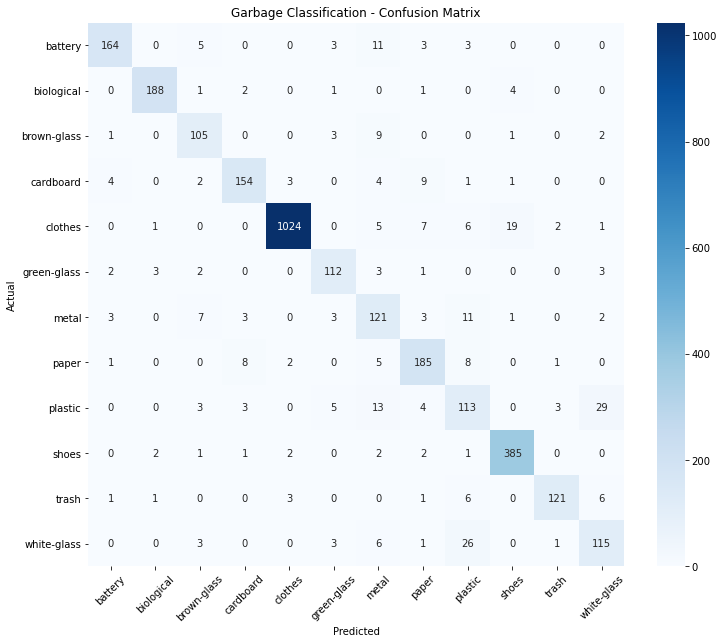

In [27]:
from sklearn.metrics import classification_report, confusion_matrix
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np

test_gen.reset()

predictions = model.predict(test_gen)
y_pred = np.argmax(predictions, axis=1)
y_true = test_gen.classes

labels = list(test_gen.class_indices.keys())

print(classification_report(
    y_true,
    y_pred,
    target_names=labels
))

plt.figure(figsize=(12, 10))

sns.heatmap(
    confusion_matrix(y_true, y_pred),
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=labels,
    yticklabels=labels
)

plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Garbage Classification - Confusion Matrix")
plt.xticks(rotation=45)
plt.yticks(rotation=0)
plt.show()

In [28]:
model.save("/kaggle/working/garbage_classification_model.h5")

print("Model saved successfully!")

Model saved successfully!


In [29]:
# Save model architecture separately
model_json = model.to_json()

with open("/kaggle/working/model_architecture.json", "w") as json_file:
    json_file.write(model_json)

# Save trained weights separately
model.save_weights("/kaggle/working/model_weights.weights.h5")

print("Architecture and weights saved successfully!")

Architecture and weights saved successfully!
